# 02 — Drift dữ liệu (Evidently, Jensen–Shannon)

So hai kịch bản trên cụm EKS, từ file bằng chứng đã commit:
- `stable`: N ngày đầu so với phần còn lại (không có thay đổi cố ý);
- `channel_shift`: N ngày đầu so với chỉ một kênh bán hàng sau mốc tham chiếu (cơ cấu đơn dồn về một sàn).

Nguồn: [`drift-summary-eks.json`](../docs/evidence/aws/drift-summary-eks.json) (chạy lại 04/11) và
[`mle-drift-20261031.json`](../docs/evidence/aws/mle-drift-20261031.json) (lần đầu 31/10).

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
EVIDENCE = ROOT / "docs" / "evidence"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
runs = {
    "04/11": json.loads((EVIDENCE / "aws" / "drift-summary-eks.json").read_text()),
    "31/10": json.loads((EVIDENCE / "aws" / "mle-drift-20261031.json").read_text()),
}
records = [
    {"lần chạy": day, "kịch bản": scenario, "cột": col, **info,
     "dòng tham chiếu": data[scenario]["reference_rows"], "dòng hiện tại": data[scenario]["current_rows"]}
    for day, data in runs.items() for scenario in data for col, info in data[scenario]["columns"].items()
]
df = pd.DataFrame(records)
df[["lần chạy", "kịch bản", "cột", "score", "threshold", "drift", "dòng tham chiếu", "dòng hiện tại"]]

,lần chạy,kịch bản,cột,score,threshold,drift,dòng tham chiếu,dòng hiện tại
0,04/11,stable,seller_sku,0.066418,0.2,False,72109,287348
1,04/11,stable,label,0.000776,0.1,False,72109,287348
2,04/11,channel_shift,seller_sku,0.202800,0.2,True,72109,8320
3,04/11,channel_shift,label,0.029788,0.1,False,72109,8320
4,31/10,stable,seller_sku,0.066418,0.2,False,72109,287348
5,31/10,stable,label,0.000776,0.1,False,72109,287348
6,31/10,channel_shift,seller_sku,0.202800,0.2,True,72109,8320
7,31/10,channel_shift,label,0.029788,0.1,False,72109,8320


## Hai lần chạy có cho cùng kết quả không?

In [3]:
a = df[df["lần chạy"] == "04/11"].set_index(["kịch bản", "cột"])
b = df[df["lần chạy"] == "31/10"].set_index(["kịch bản", "cột"])
diff = (a["score"] - b["score"]).abs()
print("chênh lệch score lớn nhất giữa hai lần chạy:", f"{diff.max():.2e}")
assert diff.max() < 1e-9 and (a["drift"] == b["drift"]).all(), "hai lần chạy phải trùng"

chênh lệch score lớn nhất giữa hai lần chạy: 2.78e-17


Hai lần chạy trùng đến sai số làm tròn, đúng như kỳ vọng vì cùng dữ liệu nguồn: kết quả này **tái lập được** giữa hai lần bật cụm.

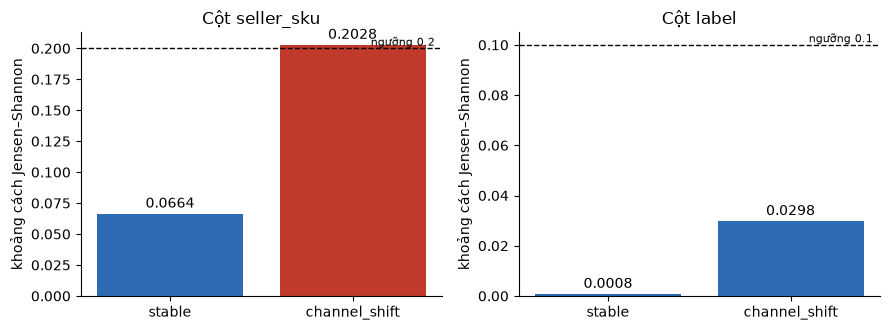

In [4]:
view = df[df["lần chạy"] == "04/11"]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=False)
for ax, col in zip(axes, ["seller_sku", "label"]):
    sub = view[view["cột"] == col].set_index("kịch bản")
    colors = ["#c0392b" if d else "#2d6cb5" for d in sub["drift"]]
    bars = ax.bar(sub.index, sub["score"], color=colors)
    ax.bar_label(bars, fmt="%.4f", padding=2)
    ax.axhline(sub["threshold"].iloc[0], color="black", ls="--", lw=1)
    ax.text(0.98, sub["threshold"].iloc[0], f" ngưỡng {sub['threshold'].iloc[0]}", ha="right", va="bottom",
            transform=ax.get_yaxis_transform(), fontsize=8)
    ax.set_title(f"Cột {col}")
    ax.set_ylabel("khoảng cách Jensen–Shannon")
plt.tight_layout()
plt.show()

In [5]:
shift = view[(view["kịch bản"] == "channel_shift") & (view["cột"] == "seller_sku")].iloc[0]
margin = shift["score"] - shift["threshold"]
print(f"channel_shift / seller_sku: {shift['score']:.4f} so với ngưỡng {shift['threshold']} -> vượt {margin:.4f} ({margin / shift['threshold']:.1%})")
stable = view[(view["kịch bản"] == "stable") & (view["cột"] == "seller_sku")].iloc[0]
print(f"stable / seller_sku       : {stable['score']:.4f} -> cách ngưỡng {stable['threshold'] - stable['score']:.4f}")

channel_shift / seller_sku: 0.2028 so với ngưỡng 0.2 -> vượt 0.0028 (1.4%)
stable / seller_sku       : 0.0664 -> cách ngưỡng 0.1336


**Đọc kết quả.** Kịch bản ổn định không báo (0,066 so với ngưỡng 0,2) và cột `label` không đổi ở cả hai. Lệch kênh bị báo ở `seller_sku`,
nhưng chỉ **vượt ngưỡng khoảng 1,4%**: điểm 0,2028 so với 0,2. Detector có hoạt động, song ca này nằm sát ngưỡng,
nên một lần chạy với lô khác có thể rơi xuống dưới. Với dữ liệu thật nên đặt ngưỡng theo phân phối điểm của nhiều cặp "stable"
thay vì dùng một giá trị cố định.